# EDA

## General Overview

### Dataset Integrity

Each check below shows the pandas calculation so we can inspect and change it. The shared library handles reading the large CSI files, decoding payloads, calculating packet metrics, and reconstructing event intervals.

In [1]:
import json
from pathlib import Path

import pandas as pd
from fall_detection.analysis import analyze_session
from fall_detection.collection.protocol import load_protocol

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").exists())
sessions_dir = ROOT / "data/raw/sessions"
latest_manifest = max(
    sessions_dir.glob("*/session.json"),
    key=lambda path: pd.Timestamp(json.loads(path.read_text())["started_at_utc"]),
)
session = json.loads(latest_manifest.read_text())
print("Latest session:", session["session_id"], "| Status:", session["status"])

Latest session: 20261026T174653764289Z | Status: complete


In [2]:
data = analyze_session(
    latest_manifest.parent,
    cache_dir=ROOT / "data/interim/integrity",
    workers=4,
)
attempts = data.attempts
receiver_data = data.receiver_attempts
phases = data.phase_intervals
phase_checks = data.phase_attempts
phase_packets = data.phase_packet_counts

#### 1. Attempts by activity and status

Count retries separately. Activity labels use confirmed truth, then review corrections, then planned labels.

In [3]:
attempt_counts = pd.crosstab(attempts["activity_label"], attempts["status"], margins=True)
display(attempt_counts)

planned_trials = load_protocol(latest_manifest.parent / "protocol.json").trials
unstarted_trials = sorted({trial.ordinal for trial in planned_trials} - set(attempts["trial_ordinal"]))
print("Planned trials:", len(planned_trials), "| Trials never started:", unstarted_trials)

status,accepted,invalid,rejected,All
activity_label,,,,
sit_to_fall,18,4,0,22
sit_to_stand,8,0,1,9
sit_to_walk,32,2,1,35
stand_to_fall,32,7,0,39
walk_to_fall,32,2,0,34
walk_to_sit,32,0,0,32
All,154,15,2,171


Planned trials: 160 | Trials never started: [43, 44, 47, 48, 51, 52]


#### 2. CSI rows per receiver

Compare all recorded rows with sensing-link rows. The sensing-link filter uses the session transmitter MAC, HE (`sig_mode == 4`), MCS 0, and 20 MHz. Each receiver remains separate.

In [4]:
csi_counts = receiver_data.groupby("receiver_id")[["raw_csi_rows", "sensing_link_rows"]].sum()
csi_counts["other_rows"] = csi_counts["raw_csi_rows"] - csi_counts["sensing_link_rows"]
display(csi_counts)

,raw_csi_rows,sensing_link_rows,other_rows
receiver_id,,,
rx-1,229747,229655,92
rx-2,240441,229671,10770


#### 3. Effective sampling rate

Pool the number of timestamp intervals and their elapsed time within attempts. This excludes pauses between attempts. Receiver timestamps are unwrapped before calculating intervals.

In [5]:
sampling = receiver_data.groupby("receiver_id").agg(
    intervals=("timestamp_interval_count", "sum"),
    elapsed_seconds=("timestamp_elapsed_seconds", "sum"),
    median_attempt_rate_hz=("effective_sampling_rate_hz", "median"),
)
sampling["effective_rate_hz"] = sampling["intervals"] / sampling["elapsed_seconds"].replace(0, float("nan"))
sampling["nominal_rate_hz"] = session["environment"]["nominal_rate_hz"]
display(sampling)

,intervals,elapsed_seconds,median_attempt_rate_hz,effective_rate_hz,nominal_rate_hz
receiver_id,,,,,
rx-1,229484,2294.855074,99.999344,99.999343,100
rx-2,229500,2295.012083,99.999471,99.999474,100


#### 4. Packet loss and timestamp gaps

Sequence gaps estimate missing packets between the first and last received sensing packets in each attempt. They do not measure missing packets at the recording edges. A timestamp gap exceeds 1.5 nominal sample periods.

In [6]:
packet_quality = receiver_data.groupby("receiver_id").agg(
    received=("sensing_link_rows", "sum"),
    missing=("sequence_missing_frames", "sum"),
    timestamp_gaps=("timestamp_gap_intervals", "sum"),
    longest_interval_ms=("max_interval_ms", "max"),
    timestamp_resets=("timestamp_resets", "sum"),
)
expected_in_span = packet_quality["received"] + packet_quality["missing"]
packet_quality["estimated_loss_pct"] = 100 * packet_quality["missing"] / expected_in_span.replace(0, float("nan"))
display(packet_quality)

display(receiver_data.nlargest(10, "max_interval_ms")[[
    "attempt_id", "receiver_id", "status", "max_interval_ms", "sequence_missing_frames",
]])

,received,missing,timestamp_gaps,longest_interval_ms,timestamp_resets,estimated_loss_pct
receiver_id,,,,,,
rx-1,229655,0,0,10.412,0,0.0
rx-2,229671,0,0,10.412,0,0.0


,attempt_id,receiver_id,status,max_interval_ms,sequence_missing_frames
192,090/01,rx-1,accepted,10.412,0
193,090/01,rx-2,accepted,10.412,0
43,021/01,rx-2,invalid,10.266,0
159,074/02,rx-2,accepted,10.266,0
307,144/01,rx-2,accepted,10.266,0
147,069/01,rx-2,accepted,10.263,0
319,150/01,rx-2,accepted,10.257,0
339,159/01,rx-2,accepted,10.257,0
1,001/01,rx-2,accepted,10.255,0
125,060/01,rx-2,accepted,10.255,0


#### 5. Missing or empty receivers

The loader creates one row per expected receiver and attempt, including missing recordings. A header-only CSI file exists but has zero rows.

In [7]:
missing_receivers = receiver_data.loc[
    ~receiver_data["receiver_dir_exists"]
    | ~receiver_data["csi_file_exists"]
    | ~receiver_data["timing_file_exists"]
    | receiver_data["sensing_link_rows"].eq(0),
    ["attempt_id", "receiver_id", "status", "receiver_dir_exists", "csi_file_exists", "timing_file_exists", "sensing_link_rows"],
]
display(missing_receivers)

,attempt_id,receiver_id,status,receiver_dir_exists,csi_file_exists,timing_file_exists,sensing_link_rows


#### 6. Usable subcarriers after phase masking

The physical-slot mask excludes null, guard, and invalid first-word slots. Finite samples with amplitude at least 4.0 remain usable. Compute the packet-weighted mean count and fraction of eligible slots retained.

In [8]:
subcarriers = receiver_data.groupby("receiver_id").agg(
    packets=("phase_mask_supported_rows", "sum"),
    usable_samples=("phase_usable_subcarriers_sum", "sum"),
    eligible_slots=("phase_max_subcarriers_sum", "sum"),
    unreadable_payloads=("phase_mask_unreadable_rows", "sum"),
    unsupported_layouts=("phase_mask_unsupported_rows", "sum"),
)
subcarriers["mean_usable_per_packet"] = subcarriers["usable_samples"] / subcarriers["packets"].replace(0, float("nan"))
subcarriers["usable_pct"] = 100 * subcarriers["usable_samples"] / subcarriers["eligible_slots"].replace(0, float("nan"))
display(subcarriers)

,packets,usable_samples,eligible_slots,unreadable_payloads,unsupported_layouts,mean_usable_per_packet,usable_pct
receiver_id,,,,,,,
rx-1,229655,55257392,55576510,0,0,240.610446,99.425804
rx-2,229671,55136856,55580382,0,0,240.068864,99.202010


#### 7. Countdown, action, and recovery reconstruction

Intervals use `phase_changed` events and the capture's ending timestamp. Action can end early after operator confirmation. Inspect both the observed durations and the phase sequences; invalid attempts may legitimately end before recovery.

In [9]:
phase_durations = phases.groupby("phase").agg(
    attempts=("attempt_id", "count"),
    planned_seconds=("planned_seconds", "median"),
    observed_median_seconds=("observed_seconds", "median"),
    observed_min_seconds=("observed_seconds", "min"),
    observed_max_seconds=("observed_seconds", "max"),
).reindex(["countdown", "action", "recovery"])
display(phase_durations)
display(phase_checks.groupby(["status", "phase_sequence"]).size().rename("attempts"))

,attempts,planned_seconds,observed_median_seconds,observed_min_seconds,observed_max_seconds
phase,,,,,
countdown,171,5.0,5.035228,1.823429,5.146591
action,167,8.0,4.079526,0.369924,7.156162
recovery,159,5.0,6.128768,2.582778,15.682827


status    phase_sequence               
accepted  countdown → action → recovery    154
invalid   countdown                          4
          countdown → action                 8
          countdown → action → recovery      3
rejected  countdown → action → recovery      2
Name: attempts, dtype: int64

In [10]:
phase_ok = phase_checks[["phase_order_valid", "phase_bounds_valid", "action_confirmation_matches"]].all(axis=1)
phase_errors = phase_checks.loc[
    ~phase_ok
    | phase_checks["completed_attempt_has_all_phases"].eq(False)
    | phase_checks["confirmation_occurs_during_action"].eq(False)
    | phase_checks["trial_resolution_matches_status"].eq(False)
]
display(phase_errors)

phase_counts = phase_packets.groupby(["phase", "receiver_id"])["sensing_link_csi_rows"].sum().unstack("receiver_id")
display(phase_counts.reindex(["countdown", "action", "recovery"]))

,attempt_id,trial_ordinal,activity_label,status,phase_sequence,phase_order_valid,phase_bounds_valid,all_phases_present,completed_attempt_has_all_phases,action_confirmed_manifest,action_confirmed_event,action_confirmation_matches,confirmation_occurs_during_action,trial_resolution_matches_status,countdown_seconds,action_seconds,recovery_seconds


receiver_id,rx-1,rx-2
phase,,
countdown,84238,84228
action,66832,66842
recovery,78521,78528


#### CSV alignment and malformed rows

CSI and radio timing rows should match by position, sequence, and receiver timestamp. Packet-to-phase assignment uses host receive time, so USB buffering makes the phase counts approximate. These checks describe recording integrity; model performance still requires evaluation.

In [12]:
error_columns = [
    "row_count_difference", "csi_timing_sequence_mismatches", "csi_timing_timestamp_mismatches",
    "malformed_sensing_metadata_rows", "phase_mask_unreadable_rows", "phase_mask_unsupported_rows",
    "sequence_out_of_order", "sequence_duplicates", "timestamp_resets",
]
recording_errors = receiver_data.loc[
    receiver_data[error_columns].ne(0).any(axis=1) | receiver_data["read_error"].ne(""),
    ["attempt_id", "receiver_id", *error_columns, "read_error"],
]
display(recording_errors)

,attempt_id,receiver_id,row_count_difference,csi_timing_sequence_mismatches,csi_timing_timestamp_mismatches,malformed_sensing_metadata_rows,phase_mask_unreadable_rows,phase_mask_unsupported_rows,sequence_out_of_order,sequence_duplicates,timestamp_resets,read_error


The library keeps file parsing, CSI decoding, timestamp unwrapping, event interval reconstruction, parallel scanning, and caching out of the notebook. Tables above are ordinary pandas DataFrames: change the groupings, filters, or calculations directly here. Set `refresh=True` in the load call to rebuild the derived cache.

### 2. Phase signal sanity

Compare a fall and a non-fall attempt from this session. The default pair is `walk_to_fall` and `walk_to_sit`; selection uses recording integrity and attempt order, not the size of a phase disturbance. Each figure shows both receivers on their own event-aligned timelines. The plotting dependency is included in the `analysis` extra (`uv sync --extra radio --extra analysis`). This is a visual diagnostic, not evidence that a representation improves fall classification.

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from fall_detection.analysis.phase_signals import load_phase_signal

ACTIVITIES = {"Fall": "walk_to_fall", "Non-fall": "walk_to_sit"}
ATTEMPT_OVERRIDES = {}  # Example: {"walk_to_fall": "003/01"}
RECEIVERS = ["rx-1", "rx-2"]
BASELINE_SECONDS = 1.0
MOTION_LAG_SECONDS = 0.10
TRACE_SUBCARRIERS = 6
HEATMAP_LIMIT_RAD = 1.0  # Shared scale; larger changes saturate.
FIGURE_DIR = ROOT / "docs/figures/phase-sanity" / session["session_id"]

#### Choose attempts explicitly

Require accepted attempts, all three phases, and no missing receiver or structural recording errors from the integrity checks. Exclude attempts marked `exclude` or `bad` in the review sidecar. The overrides above let us inspect any other eligible attempt without changing the plotting code.

In [14]:
excluded_ids = set(missing_receivers["attempt_id"]) | set(recording_errors["attempt_id"]) | set(phase_errors["attempt_id"])
review_path = latest_manifest.parent / "session_review.json"
review_entries = json.loads(review_path.read_text()).get("attempts", {}) if review_path.exists() else {}
for relative_path, review in review_entries.items():
    if review.get("inclusion") == "exclude" or review.get("quality") == "bad":
        attempt_path = latest_manifest.parent / relative_path / "attempt.json"
        metadata = json.loads(attempt_path.read_text())
        number = int(attempt_path.parent.name.removeprefix("attempt_"))
        excluded_ids.add(f"{metadata['trial_ordinal']:03d}/{number:02d}")

complete_ids = set(phase_checks.loc[phase_checks["all_phases_present"], "attempt_id"])
candidates = attempts.loc[
    attempts["status"].eq("accepted")
    & attempts["attempt_id"].isin(complete_ids)
    & ~attempts["attempt_id"].isin(excluded_ids)
].sort_values(["trial_ordinal", "attempt_number"])

selected_attempts = []
for case, activity in ACTIVITIES.items():
    choices = candidates.loc[candidates["activity_label"].eq(activity)]
    if activity in ATTEMPT_OVERRIDES:
        choices = choices.loc[choices["attempt_id"].eq(ATTEMPT_OVERRIDES[activity])]
    if choices.empty:
        raise ValueError(f"No eligible attempt for {activity}; inspect the integrity tables or change ACTIVITIES.")
    selected_attempts.append({"case": case, "activity": activity, "attempt_id": choices.iloc[0]["attempt_id"]})
display(pd.DataFrame(selected_attempts))

,case,activity,attempt_id
0,Fall,walk_to_fall,001/01
1,Non-fall,walk_to_sit,089/01


In [15]:
phase_signals = {
    (item["attempt_id"], receiver): load_phase_signal(latest_manifest.parent, item["attempt_id"], receiver)
    for item in selected_attempts for receiver in RECEIVERS
}
display(pd.DataFrame([
    {
        "attempt_id": key[0], "receiver": key[1], "packets": len(signal.time_seconds),
        "physical_slots": len(signal.subcarriers), "time_source": signal.time_source,
        "sync_fit_uncertainty_us": signal.sync_uncertainty_us,
        "skipped_layout_rows": signal.skipped_layout_rows,
    }
    for key, signal in phase_signals.items()
]))

,attempt_id,receiver,packets,physical_slots,time_source,sync_fit_uncertainty_us,skipped_layout_rows
0,001/01,rx-1,1400,245,receiver callback → host (USB affine fit),69.310155,0
1,001/01,rx-2,1399,245,receiver callback → host (USB affine fit),146.333935,0
2,089/01,rx-1,1584,245,receiver callback → host (USB affine fit),49.795154,0
3,089/01,rx-2,1584,245,receiver callback → host (USB affine fit),55.054426,0


#### Define the baseline and motion score

Raw and calibrated phase share the production physical-slot and amplitude masks. Baseline-relative change is `wrap(calibrated phase − baseline)`, where the baseline is each subcarrier's **circular mean over the first 1.0 seconds of countdown** (configurable above). No action or recovery samples enter that reference.

The scalar motion score is the median absolute circular phase change across eligible subcarriers over a 100 ms lag. It is measured in radians per lag, not radians per second. Compare raw and calibrated scores using the same baseline-eligible tones; a score requires at least half those tones (and at least three) to have valid values at both endpoints. Missing lag endpoints remain missing. No temporal filtering or resampling is applied.

In [16]:
from fall_detection.analysis.phase_motion import phase_motion_score

def wrap_phase(values):
    return np.angle(np.exp(1j * values))

In [17]:
phase_views = {}
for key, signal in phase_signals.items():
    bounds = phases.loc[phases["attempt_id"].eq(key[0]), ["phase", "phase_start_monotonic_ns", "phase_end_monotonic_ns"]].copy()
    bounds["start_s"] = (bounds["phase_start_monotonic_ns"] - signal.started_monotonic_ns) / 1e9
    bounds["end_s"] = (bounds["phase_end_monotonic_ns"] - signal.started_monotonic_ns) / 1e9
    countdown = bounds.loc[bounds["phase"].eq("countdown")].iloc[0]
    baseline_start = countdown["start_s"]
    baseline_end = min(baseline_start + BASELINE_SECONDS, countdown["end_s"])
    baseline_rows = (signal.time_seconds >= baseline_start) & (signal.time_seconds < baseline_end)

    baseline_samples = signal.calibrated_phase[baseline_rows]
    baseline_count = np.isfinite(baseline_samples).sum(axis=0)
    circular_sum = np.nansum(np.exp(1j * baseline_samples), axis=0)
    eligible = (baseline_count >= 3) & (np.abs(circular_sum) > 1e-6 * baseline_count)
    if eligible.sum() < 3:
        raise ValueError(f"Too few valid countdown baseline tones for {key}")
    baseline = np.full(len(signal.subcarriers), np.nan)
    baseline[eligible] = np.angle(circular_sum[eligible])
    relative_phase = wrap_phase(signal.calibrated_phase - baseline)

    trace_candidates = np.flatnonzero(eligible & (np.isfinite(relative_phase).mean(axis=0) >= 0.8))
    if not len(trace_candidates):
        raise ValueError(f"No consistently usable trace subcarriers for {key}")
    trace_indices = trace_candidates[np.unique(np.round(np.linspace(0.1, 0.9, min(TRACE_SUBCARRIERS, len(trace_candidates))) * (len(trace_candidates) - 1)).astype(int))]
    phase_views[key] = {
        "bounds": bounds, "baseline_interval": (baseline_start, baseline_end),
        "relative_phase": relative_phase, "trace_indices": trace_indices,
        "raw_score": phase_motion_score(signal.raw_phase[:, eligible], signal.time_seconds, MOTION_LAG_SECONDS),
        "calibrated_score": phase_motion_score(signal.calibrated_phase[:, eligible], signal.time_seconds, MOTION_LAG_SECONDS),
    }

display(pd.DataFrame([
    {"attempt_id": key[0], "receiver": key[1], "trace_subcarriers": phase_signals[key].subcarriers[view["trace_indices"]].tolist(),
     "baseline_start_s": view["baseline_interval"][0], "baseline_end_s": view["baseline_interval"][1]}
    for key, view in phase_views.items()
]))

,attempt_id,receiver,trace_subcarriers,baseline_start_s,baseline_end_s
0,001/01,rx-1,"[-98, -60, -21, 20, 59, 97]",0.001259,1.001259
1,001/01,rx-2,"[-98, -60, -21, 20, 59, 97]",0.001259,1.001259
2,089/01,rx-1,"[-98, -60, -21, 20, 59, 97]",0.004160,1.004160
3,089/01,rx-2,"[-98, -60, -21, 20, 59, 97]",0.004160,1.004160


#### Inspect phase traces, spatial coherence, and the removed trend

Each column is one receiver. The same six evenly spaced interior usable tones appear in the three trace panels; the heatmap includes all physical subcarriers, including masked null tones shown in gray. Both examples share a fixed ±1 rad heatmap scale; larger changes saturate (colorbar extensions). Vertical lines and labels mark countdown, action, and recovery on **every panel**. Gray vertical bands mark gaps longer than 1.5 nominal sample periods and intervals outside the first/last sensing packet. A dotted line marks the last sensing packet, which can precede the manifest end. USB clock alignment still includes one-way latency uncertainty. Lines break at phase wraps to avoid drawing artificial jumps across ±π.

The final panels show the magnitude-weighted linear slope and offset subtracted from each packet. Offset is displayed modulo 2π. Their time course helps identify what calibration removes; it cannot establish that the removed trend is unrelated to human motion. Compare action disturbances across multiple tones and receivers, and check whether a similar disturbance appears during the non-fall activity. Use the overrides to inspect more attempts before generalizing.

In [18]:
PHASE_COLORS = {"countdown": "#737373", "action": "#d95f02", "recovery": "#1b9e77"}

def plot_wrapped(ax, seconds, values, **kwargs):
    displayed = values.copy()
    displayed[1:][np.abs(np.diff(values)) > np.pi] = np.nan
    return ax.plot(seconds, displayed, **kwargs)

def overlay_phases(ax, bounds):
    for row in bounds.itertuples(index=False):
        color = PHASE_COLORS[row.phase]
        ax.axvspan(row.start_s, row.end_s, color=color, alpha=0.06, zorder=0)
        ax.axvline(row.start_s, color=color, linestyle="--", linewidth=0.8, zorder=5)
        ax.text((row.start_s + row.end_s) / 2, 0.97, row.phase, color=color,
                transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=8,
                bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"}, zorder=6)
    ax.axvline(bounds["end_s"].max(), color="0.4", linestyle="--", linewidth=0.8, zorder=5)

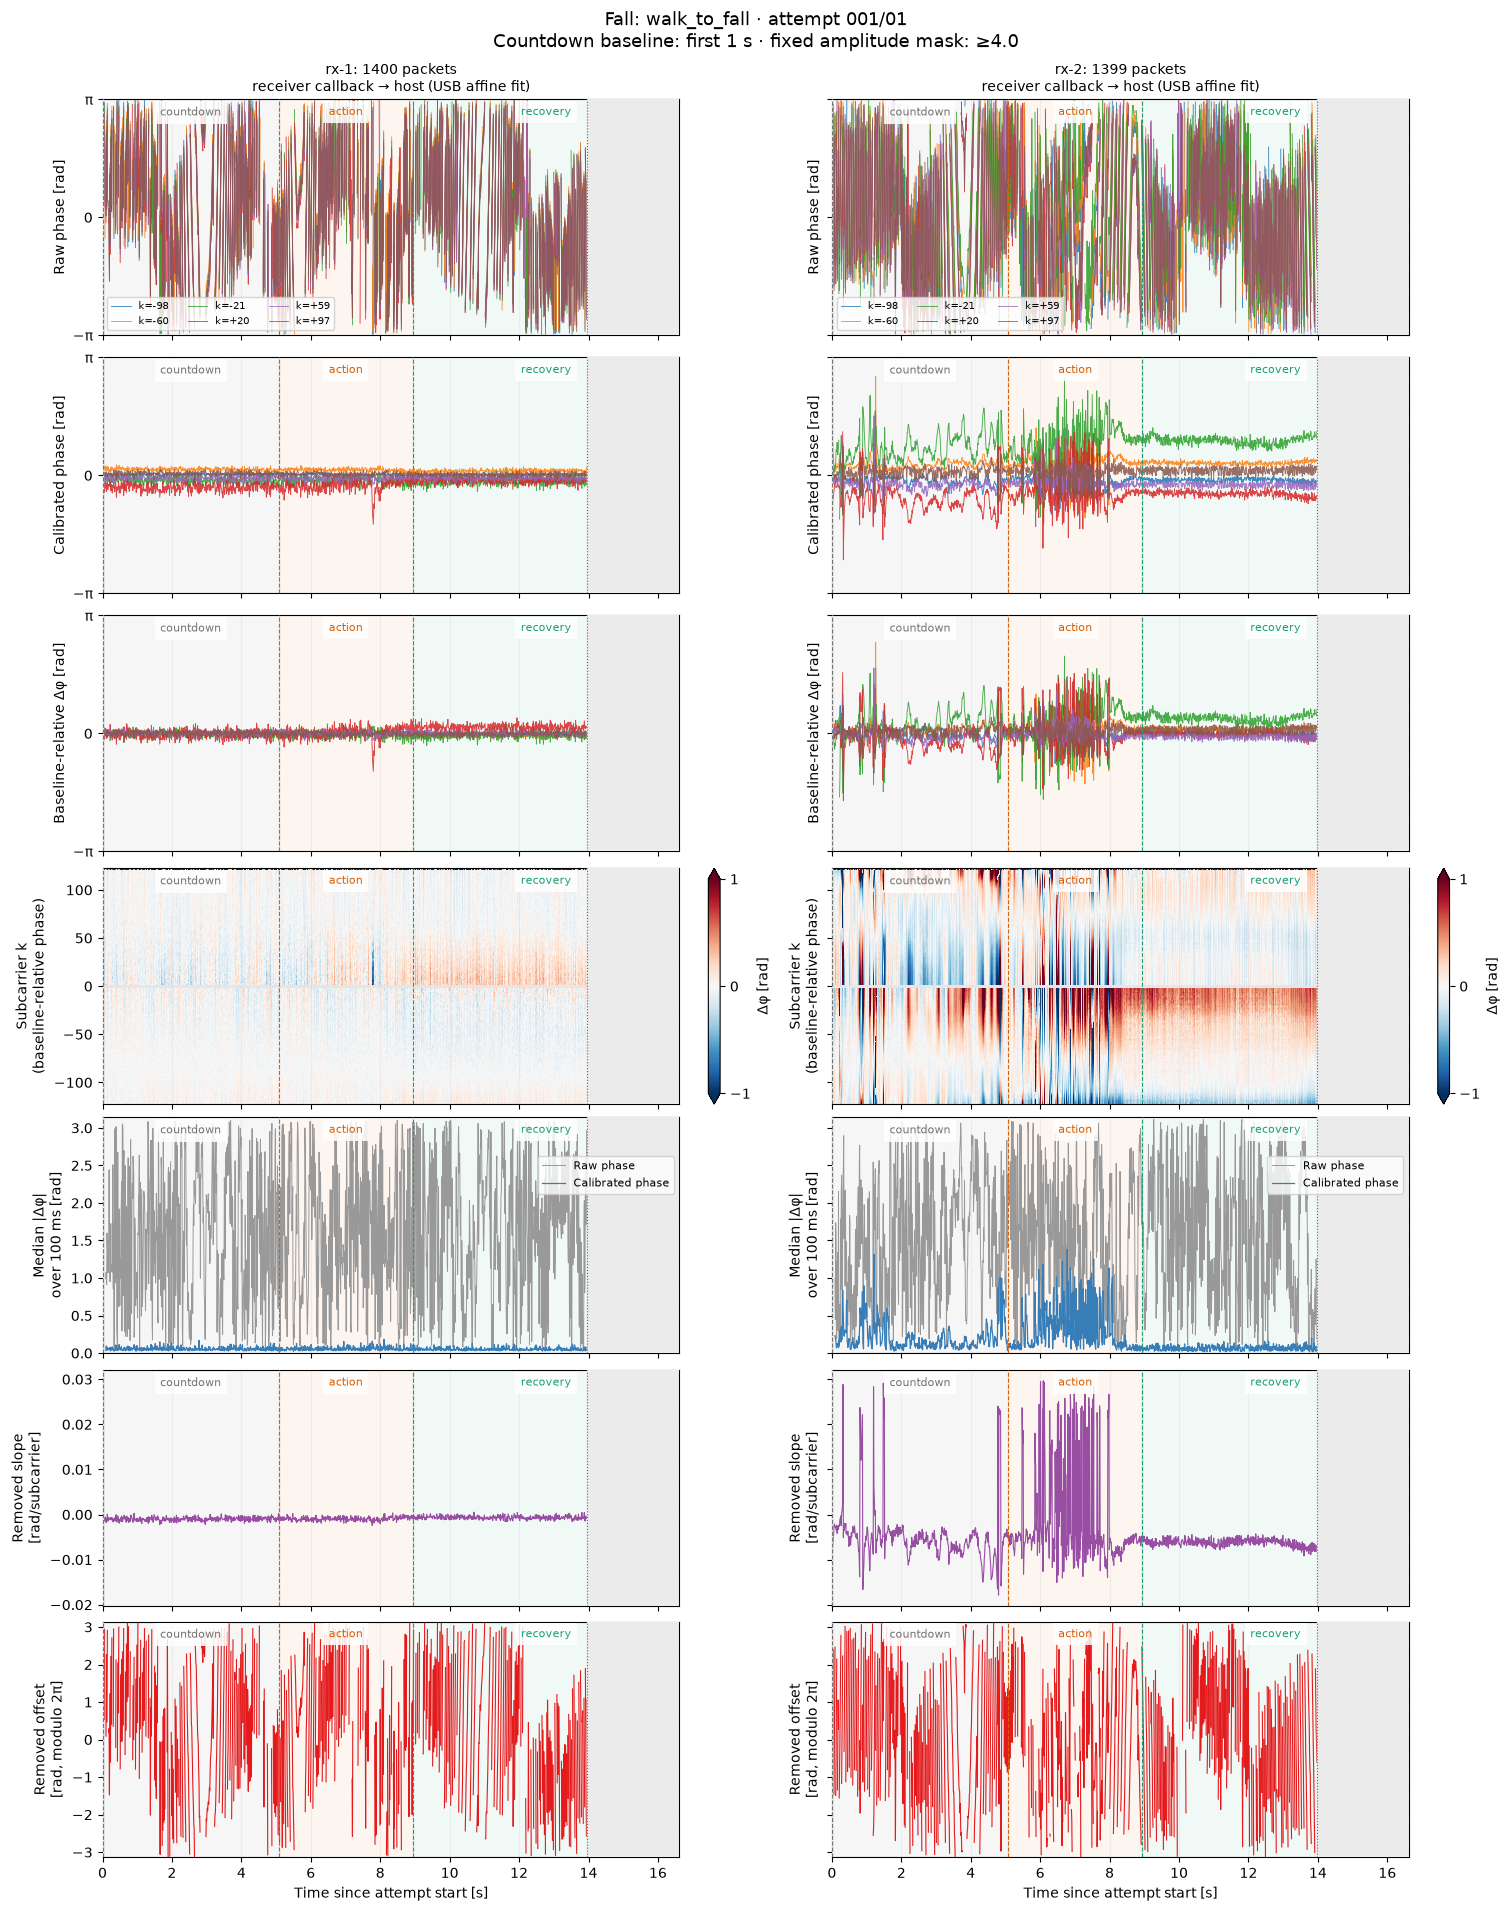

Saved: docs/figures/phase-sanity/20261026T174653764289Z/001_01_walk_to_fall_phase-sanity.png


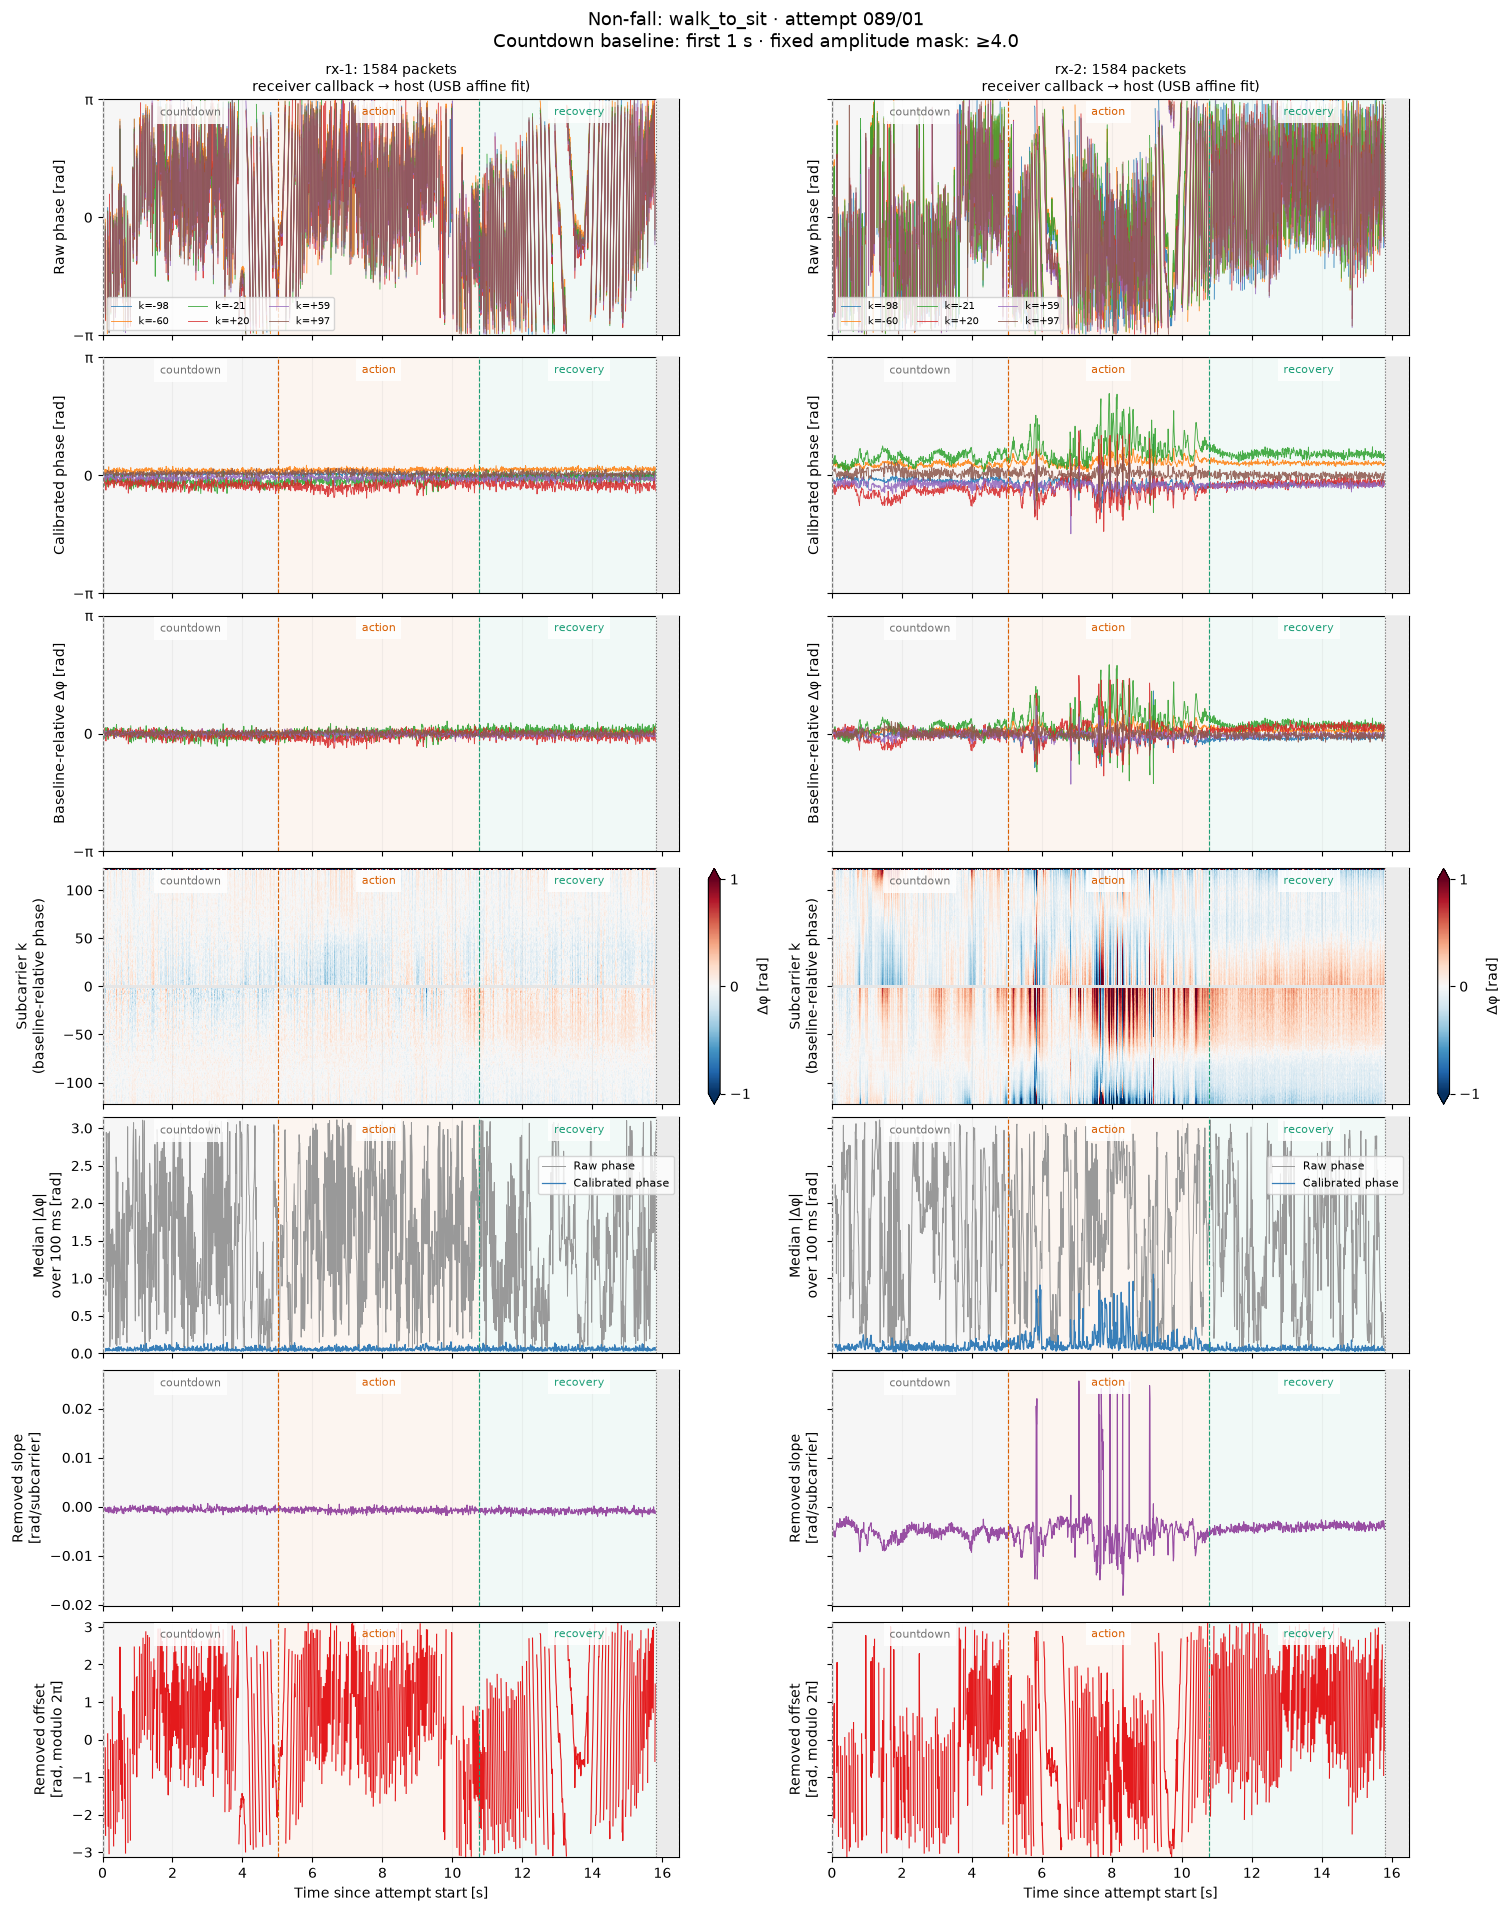

Saved: docs/figures/phase-sanity/20261026T174653764289Z/089_01_walk_to_sit_phase-sanity.png


In [19]:
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
phase_figure_paths = []
heatmap_cmap = plt.get_cmap("RdBu_r").copy()
heatmap_cmap.set_bad("0.9")

for item in selected_attempts:
    fig, axes = plt.subplots(7, len(RECEIVERS), figsize=(15, 19), sharex="col", sharey="row", squeeze=False, layout="constrained")
    for column, receiver in enumerate(RECEIVERS):
        key = (item["attempt_id"], receiver)
        signal, view = phase_signals[key], phase_views[key]
        seconds = signal.time_seconds
        matrices = [signal.raw_phase, signal.calibrated_phase, view["relative_phase"]]
        for row, (matrix, label) in enumerate(zip(matrices, ["Raw phase [rad]", "Calibrated phase [rad]", "Baseline-relative Δφ [rad]"])):
            ax = axes[row, column]
            for tone in view["trace_indices"]:
                plot_wrapped(ax, seconds, matrix[:, tone], linewidth=0.65, alpha=0.85, label=f"k={signal.subcarriers[tone]:+d}")
            ax.set(ylabel=label, ylim=(-np.pi, np.pi), yticks=[-np.pi, 0, np.pi], yticklabels=["−π", "0", "π"])
        axes[0, column].set_title(f"{receiver}: {len(seconds)} packets\n{signal.time_source}", fontsize=10)
        axes[0, column].legend(ncol=3, fontsize=7, loc="lower left")

        image = axes[3, column].pcolormesh(seconds, signal.subcarriers, view["relative_phase"].T,
            shading="nearest", cmap=heatmap_cmap, vmin=-HEATMAP_LIMIT_RAD, vmax=HEATMAP_LIMIT_RAD, rasterized=True)
        axes[3, column].set_ylabel("Subcarrier k\n(baseline-relative phase)")
        colorbar = fig.colorbar(image, ax=axes[3, column], label="Δφ [rad]", ticks=[-HEATMAP_LIMIT_RAD, 0, HEATMAP_LIMIT_RAD], extend="both")

        axes[4, column].plot(seconds, view["raw_score"], color="0.6", linewidth=0.7, label="Raw phase")
        axes[4, column].plot(seconds, view["calibrated_score"], color="#377eb8", linewidth=0.9, label="Calibrated phase")
        axes[4, column].set(ylabel=f"Median |Δφ|\nover {MOTION_LAG_SECONDS * 1000:g} ms [rad]", ylim=(0, np.pi))
        axes[4, column].legend(fontsize=8, loc="upper right", bbox_to_anchor=(1, 0.86))
        axes[5, column].plot(seconds, signal.removed_slope, color="#984ea3", linewidth=0.8)
        axes[5, column].set_ylabel("Removed slope\n[rad/subcarrier]")
        plot_wrapped(axes[6, column], seconds, wrap_phase(signal.removed_offset), color="#e41a1c", linewidth=0.8)
        axes[6, column].set(ylabel="Removed offset\n[rad, modulo 2π]", ylim=(-np.pi, np.pi), xlabel="Time since attempt start [s]")

        gap_indices = np.flatnonzero(np.diff(seconds) > 1.5 / signal.nominal_rate_hz)
        capture_end = (signal.ended_monotonic_ns - signal.started_monotonic_ns) / 1e9
        for ax in axes[:, column]:
            ax.axvspan(0, max(0, seconds[0]), color="0.92", zorder=3)
            ax.axvspan(seconds[-1], capture_end, color="0.92", zorder=3)
            ax.axvline(seconds[-1], color="0.4", linestyle=":", linewidth=0.8, zorder=5)
            for gap in gap_indices:
                ax.axvspan(seconds[gap] + 0.5 / signal.nominal_rate_hz,
                           seconds[gap + 1] - 0.5 / signal.nominal_rate_hz, color="0.92", zorder=3)
            overlay_phases(ax, view["bounds"])
            ax.set_xlim(0, capture_end)
            ax.grid(axis="x", alpha=0.15)

    fig.suptitle(f"{item['case']}: {item['activity']} · attempt {item['attempt_id']}\n"
                 f"Countdown baseline: first {BASELINE_SECONDS:g} s · fixed amplitude mask: ≥4.0", fontsize=13)
    figure_path = FIGURE_DIR / f"{item['attempt_id'].replace('/', '_')}_{item['activity']}_phase-sanity.png"
    fig.savefig(figure_path, dpi=150)
    phase_figure_paths.append(figure_path)
    plt.show()
    plt.close(fig)
    print("Saved:", figure_path.relative_to(ROOT))

### 3. Compare activity phases

**Pilot question: Does phase change during fall actions differ visibly from phase change during non-fall actions and stationary phases?**

Use every eligible accepted attempt from the latest session, not just the two examples in section 2. Keep receivers separate and reuse the same baseline eligibility, phase mask, clock alignment, and 100 ms motion score. Countdown and recovery are the protocol's intended stationary periods; the event labels do not independently verify immobility.

In [20]:
from fall_detection.analysis.phase_motion import load_phase_motion_samples

PHASE_ORDER = ["countdown", "action", "recovery"]
ACTION_ORDER = ["Fall", "Non-fall"]
ACTIVITY_KIND = {
    "walk_to_fall": "Fall", "sit_to_fall": "Fall", "stand_to_fall": "Fall",
    "walk_to_sit": "Non-fall", "sit_to_walk": "Non-fall", "sit_to_stand": "Non-fall",
}
SCORE_COLUMN = "calibrated_score"  # "raw_score" is also available for inspection.
MIN_PHASE_SCORES = 20
SCORE_LINEAR_RANGE = 0.01  # Symlog axes retain zero and show small scores plus tails.
COMPARISON_FIGURE_DIR = ROOT / "docs/figures/activity-phases" / session["session_id"]

comparison_attempts = candidates.copy()  # Accepted, complete, structurally valid, not bad/excluded.
comparison_attempts["action_kind"] = comparison_attempts["activity_label"].map(ACTIVITY_KIND)
if comparison_attempts["action_kind"].isna().any():
    raise ValueError("Add unmapped activity labels to ACTIVITY_KIND before comparing classes.")
display(pd.crosstab(comparison_attempts["activity_label"], comparison_attempts["action_kind"]))

action_kind,Fall,Non-fall
activity_label,,
sit_to_fall,18,0
sit_to_stand,0,8
sit_to_walk,0,32
stand_to_fall,32,0
walk_to_fall,32,0
walk_to_sit,0,32


#### Measure motion throughout each attempt

The shared loader does the expensive CSI processing and caches only packet scores and coverage metadata under `data/interim/phase-motion/`. Aggregation and plotting remain below. Changes to CSI, timing/sync files, phase intervals, analysis code, baseline duration, or lag invalidate the cache.

Exclude a score from a phase comparison if its lag endpoints straddle a phase boundary. Missing endpoints and insufficient valid tones stay missing; they never become zero-motion observations. No score is synthesized after the last received packet.

In [21]:
motion_data = load_phase_motion_samples(
    latest_manifest.parent,
    comparison_attempts["attempt_id"].tolist(), RECEIVERS, phases,
    baseline_seconds=BASELINE_SECONDS, lag_seconds=MOTION_LAG_SECONDS,
    cache_dir=ROOT / "data/interim/phase-motion", workers=4,
)
motion_samples = motion_data.samples.merge(
    comparison_attempts[["attempt_id", "activity_label", "action_kind"]],
    on="attempt_id", validate="many_to_one",
)
motion_samples["usable_score"] = motion_samples["within_phase_lag"] & np.isfinite(motion_samples[SCORE_COLUMN])
print("Receiver recordings:", len(motion_data.recordings), "| Cache hits:", int(motion_data.recordings["cache_hit"].sum()))
display(motion_data.recordings.loc[motion_data.recordings["read_error"].ne("")])
display(motion_data.recordings.groupby("receiver_id")["time_source"].value_counts())

Receiver recordings: 308 | Cache hits: 308


,packet_count,baseline_tones,baseline_start_s,baseline_end_s,unassigned_packets,time_source,read_error,attempt_id,receiver_id,cache_hit


receiver_id  time_source                              
rx-1         receiver callback → host (USB affine fit)    154
rx-2         receiver callback → host (USB affine fit)    154
Name: count, dtype: int64

#### Count contributions before comparing distributions

Retain an attempt/receiver pair only if each of its three phases has at least `MIN_PHASE_SCORES` valid within-phase scores. This is a configurable pilot coverage rule, not a validated training-data acceptance threshold. Report zero-coverage phases and failed recordings explicitly. Reuse the same retained pairs in all three phase distributions and in the action comparison.

In [22]:
group_keys = ["attempt_id", "receiver_id", "phase"]
expected_groups = pd.MultiIndex.from_product(
    [comparison_attempts["attempt_id"], RECEIVERS, PHASE_ORDER], names=group_keys,
)
phase_coverage = motion_samples.groupby(group_keys).agg(
    packets=("seconds", "size"), within_phase_endpoints=("within_phase_lag", "sum"),
    valid_scores=("usable_score", "sum"),
).reindex(expected_groups, fill_value=0).reset_index()
phase_coverage["usable_phase"] = phase_coverage["valid_scores"] >= MIN_PHASE_SCORES
phase_coverage["valid_fraction"] = phase_coverage["valid_scores"] / phase_coverage["within_phase_endpoints"].replace(0, float("nan"))
phase_coverage = phase_coverage.merge(
    comparison_attempts[["attempt_id", "activity_label", "action_kind"]], on="attempt_id", validate="many_to_one",
)
pair_coverage = phase_coverage.groupby(["attempt_id", "receiver_id"])["usable_phase"].all()
eligible_pairs = pair_coverage.loc[pair_coverage].reset_index()[["attempt_id", "receiver_id"]]
display(phase_coverage.loc[~phase_coverage["usable_phase"]])
display(phase_coverage.groupby(["receiver_id", "action_kind", "phase"]).agg(
    attempts=("attempt_id", "size"), phases_with_enough_scores=("usable_phase", "sum"),
    median_valid_fraction=("valid_fraction", "median"),
))
retained_counts = eligible_pairs.merge(comparison_attempts[["attempt_id", "action_kind"]], on="attempt_id")
display(retained_counts.groupby(["receiver_id", "action_kind"]).size().rename("retained_attempts"))

valid_motion = motion_samples.loc[motion_samples["usable_score"]].merge(
    eligible_pairs, on=["attempt_id", "receiver_id"], validate="many_to_one",
)
if valid_motion.empty:
    raise ValueError("No complete attempt/receiver pairs have enough phase-motion scores.")

,attempt_id,receiver_id,phase,packets,within_phase_endpoints,valid_scores,usable_phase,valid_fraction,activity_label,action_kind


attempts  phases_with_enough_scores  \
receiver_id action_kind phase                                            
rx-1        Fall        action           82                         82   
                        countdown        82                         82   
                        recovery         82                         82   
            Non-fall    action           72                         72   
                        countdown        72                         72   
                        recovery         72                         72   
rx-2        Fall        action           82                         82   
                        countdown        82                         82   
                        recovery         82                         82   
            Non-fall    action           72                         72   
                        countdown        72                         72   
                        recovery         72                         72   

                                   median_valid_fraction  
receiver_id action_kind phase                             
rx-1        Fall        action                       1.0  
                        countdown                    1.0  
                        recovery                     1.0  
            Non-fall    action                       1.0  
                        countdown                    1.0  
                        recovery                     1.0  
rx-2        Fall        action                       1.0  
                        countdown                    1.0  
                        recovery                     1.0  
            Non-fall    action                       1.0  
                        countdown                    1.0  
                        recovery                     1.0

receiver_id  action_kind
rx-1         Fall           82
             Non-fall       72
rx-2         Fall           82
             Non-fall       72
Name: retained_attempts, dtype: int64

In [23]:
attempt_phase_scores = valid_motion.groupby(
    ["attempt_id", "receiver_id", "activity_label", "action_kind", "phase"],
).agg(
    valid_scores=(SCORE_COLUMN, "size"), median_score=(SCORE_COLUMN, "median"),
    p90_score=(SCORE_COLUMN, lambda values: values.quantile(0.90)),
    q25_score=(SCORE_COLUMN, lambda values: values.quantile(0.25)),
    q75_score=(SCORE_COLUMN, lambda values: values.quantile(0.75)),
).reset_index()

phase_distribution_summary = attempt_phase_scores.groupby(["receiver_id", "phase"]).agg(
    attempts=("attempt_id", "nunique"), valid_packet_scores=("valid_scores", "sum"),
    median_of_attempt_medians=("median_score", "median"),
    attempt_medians_q25=("median_score", lambda values: values.quantile(0.25)),
    attempt_medians_q75=("median_score", lambda values: values.quantile(0.75)),
    median_of_attempt_p90=("p90_score", "median"),
)
display(phase_distribution_summary)

attempts  valid_packet_scores  \
receiver_id phase                                      
rx-1        action          154                63367   
            countdown       154                75995   
            recovery        154                75571   
rx-2        action          154                63361   
            countdown       154                75979   
            recovery        154                75569   

                       median_of_attempt_medians  attempt_medians_q25  \
receiver_id phase                                                       
rx-1        action                      0.052837             0.051144   
            countdown                   0.051200             0.049915   
            recovery                    0.050150             0.048571   
rx-2        action                      0.097920             0.068600   
            countdown                   0.071910             0.056146   
            recovery                    0.059245             0.050792   

                       attempt_medians_q75  median_of_attempt_p90  
receiver_id phase                                                  
rx-1        action                0.054742               0.087788  
            countdown             0.052872               0.085766  
            recovery              0.052045               0.084449  
rx-2        action                0.185207               0.280555  
            countdown             0.113129               0.149461  
            recovery              0.067809               0.110276

#### Compare countdown, action, and recovery

The empirical cumulative distribution (ECDF) gives **equal total weight to each attempt** within its phase/class and receiver. This prevents a long phase from dominating through its packet count. Boxplots and dots show one phase median per attempt. Dots are deterministically jittered for visibility; the score itself is unchanged.

Axes use a symlog scale with a linear region near zero to show both small disturbances and the full observed tails. No samples are clipped. Packet scores overlap in time and all attempts come from this one session; these are descriptive plots without independence-based significance claims.

In [24]:
def equal_attempt_ecdf(frame):
    ordered = frame.sort_values(SCORE_COLUMN)
    weights = 1 / ordered.groupby("attempt_id")[SCORE_COLUMN].transform("size")
    x = np.r_[0, ordered[SCORE_COLUMN].to_numpy()]
    y = np.r_[0, weights.cumsum().to_numpy() / weights.sum()]
    return x, y

def attempt_boxplot(ax, frame, group_column, order, metric, colors):
    grouped = [frame.loc[frame[group_column].eq(group), metric].dropna().to_numpy() for group in order]
    boxes = ax.boxplot(grouped, positions=np.arange(len(order)), showfliers=False, patch_artist=True)
    rng = np.random.default_rng(0)
    for position, (group, values, patch) in enumerate(zip(order, grouped, boxes["boxes"])):
        patch.set_facecolor(colors[group])
        patch.set_alpha(0.25)
        ax.scatter(position + rng.uniform(-0.12, 0.12, len(values)), values,
                   color=colors[group], alpha=0.5, s=12, linewidths=0)
    ax.set_xticks(np.arange(len(order)), [f"{group}\nn={len(values)}" for group, values in zip(order, grouped)])
    ax.set_yscale("symlog", linthresh=SCORE_LINEAR_RANGE)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.2)

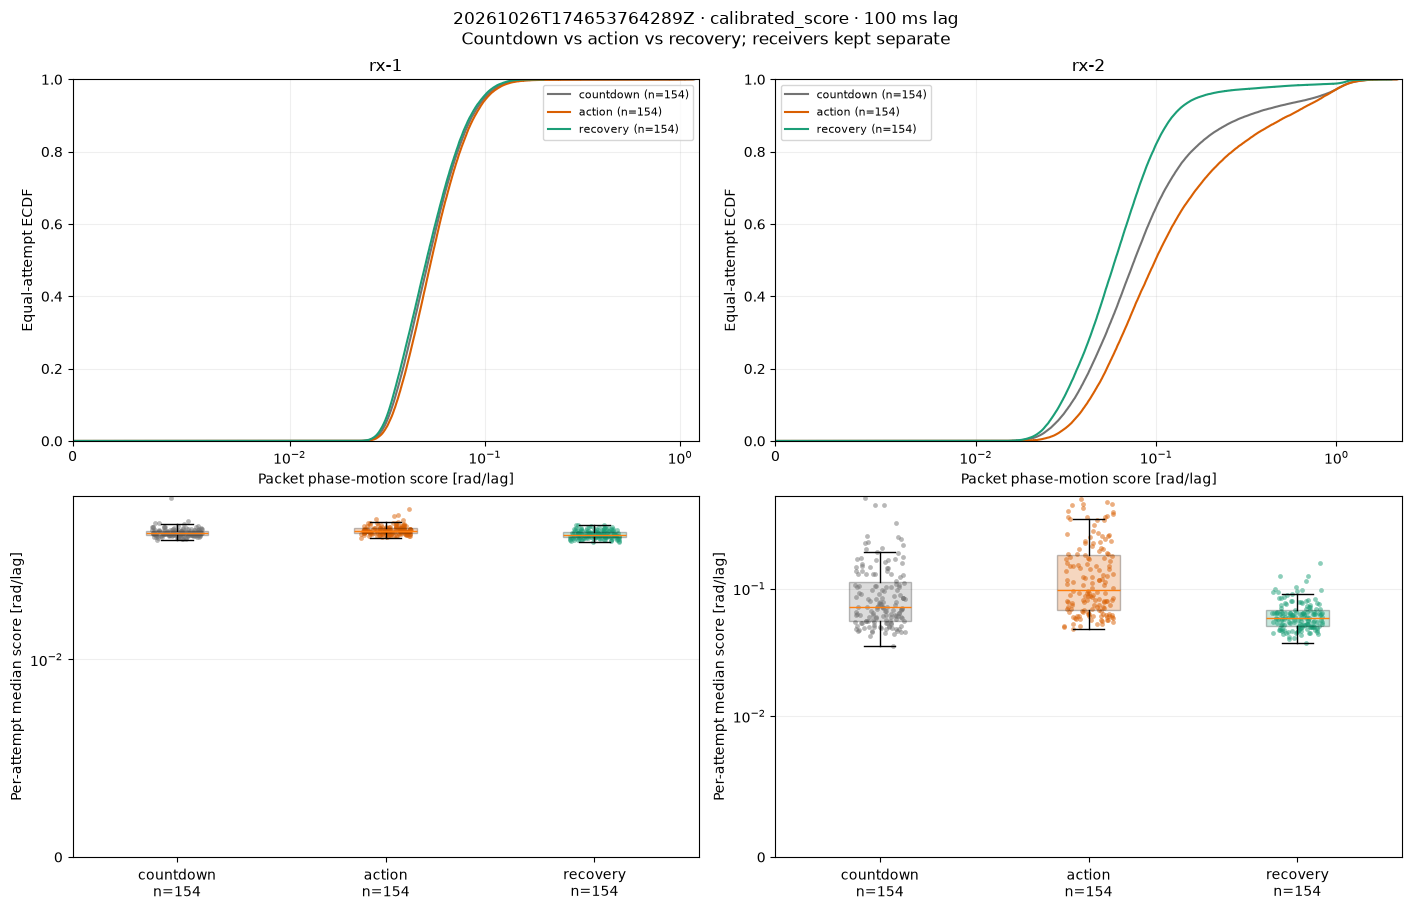

In [25]:
COMPARISON_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(2, len(RECEIVERS), figsize=(14, 9), squeeze=False, layout="constrained")
for column, receiver in enumerate(RECEIVERS):
    packets = valid_motion.loc[valid_motion["receiver_id"].eq(receiver)]
    summaries = attempt_phase_scores.loc[attempt_phase_scores["receiver_id"].eq(receiver)]
    for phase in PHASE_ORDER:
        subset = packets.loc[packets["phase"].eq(phase)]
        if not subset.empty:
            x, y = equal_attempt_ecdf(subset)
            axes[0, column].step(x, y, where="post", color=PHASE_COLORS[phase],
                                 label=f"{phase} (n={subset['attempt_id'].nunique()})")
    axes[0, column].set(title=receiver, xlabel="Packet phase-motion score [rad/lag]", ylabel="Equal-attempt ECDF", ylim=(0, 1))
    axes[0, column].set_xscale("symlog", linthresh=SCORE_LINEAR_RANGE)
    axes[0, column].set_xlim(left=0)
    axes[0, column].legend(fontsize=8)
    axes[0, column].grid(alpha=0.2)
    attempt_boxplot(axes[1, column], summaries, "phase", PHASE_ORDER, "median_score", PHASE_COLORS)
    axes[1, column].set_ylabel("Per-attempt median score [rad/lag]")
fig.suptitle(f"{session['session_id']} · {SCORE_COLUMN} · {MOTION_LAG_SECONDS * 1000:g} ms lag\nCountdown vs action vs recovery; receivers kept separate")
phase_distribution_path = COMPARISON_FIGURE_DIR / "phase-distributions.png"
fig.savefig(phase_distribution_path, dpi=150)
plt.show()
plt.close(fig)

#### Separate fall and non-fall actions

Restrict to action packets, then compare the two explicit activity groups. The median describes typical motion within an attempt; the 90th percentile also shows short, stronger disturbances that a median can hide. Neither statistic is a detector or a selected decision threshold. Keep the per-activity table visible because pooled fall/non-fall groups mix different movements.

In [26]:
action_packets = valid_motion.loc[valid_motion["phase"].eq("action")]
action_attempts = attempt_phase_scores.loc[attempt_phase_scores["phase"].eq("action")]
display(action_attempts.groupby(["receiver_id", "action_kind"]).agg(
    attempts=("attempt_id", "nunique"), median_score=("median_score", "median"),
    median_p90_score=("p90_score", "median"),
))
display(action_attempts.groupby(["receiver_id", "activity_label", "action_kind"]).agg(
    attempts=("attempt_id", "nunique"), median_score=("median_score", "median"),
    median_p90_score=("p90_score", "median"),
))

attempts  median_score  median_p90_score
receiver_id action_kind                                          
rx-1        Fall               82      0.052597          0.087952
            Non-fall           72      0.053154          0.087482
rx-2        Fall               82      0.090906          0.182325
            Non-fall           72      0.112751          0.311049

attempts  median_score  \
receiver_id activity_label action_kind                           
rx-1        sit_to_fall    Fall               18      0.051440   
            sit_to_stand   Non-fall            8      0.052325   
            sit_to_walk    Non-fall           32      0.053799   
            stand_to_fall  Fall               32      0.051600   
            walk_to_fall   Fall               32      0.054986   
            walk_to_sit    Non-fall           32      0.053154   
rx-2        sit_to_fall    Fall               18      0.063307   
            sit_to_stand   Non-fall            8      0.221638   
            sit_to_walk    Non-fall           32      0.108989   
            stand_to_fall  Fall               32      0.156097   
            walk_to_fall   Fall               32      0.078820   
            walk_to_sit    Non-fall           32      0.096920   

                                        median_p90_score  
receiver_id activity_label action_kind                    
rx-1        sit_to_fall    Fall                 0.086347  
            sit_to_stand   Non-fall             0.089445  
            sit_to_walk    Non-fall             0.088146  
            stand_to_fall  Fall                 0.086405  
            walk_to_fall   Fall                 0.091077  
            walk_to_sit    Non-fall             0.086778  
rx-2        sit_to_fall    Fall                 0.115742  
            sit_to_stand   Non-fall             0.678482  
            sit_to_walk    Non-fall             0.300218  
            stand_to_fall  Fall                 0.816825  
            walk_to_fall   Fall                 0.254975  
            walk_to_sit    Non-fall             0.238708

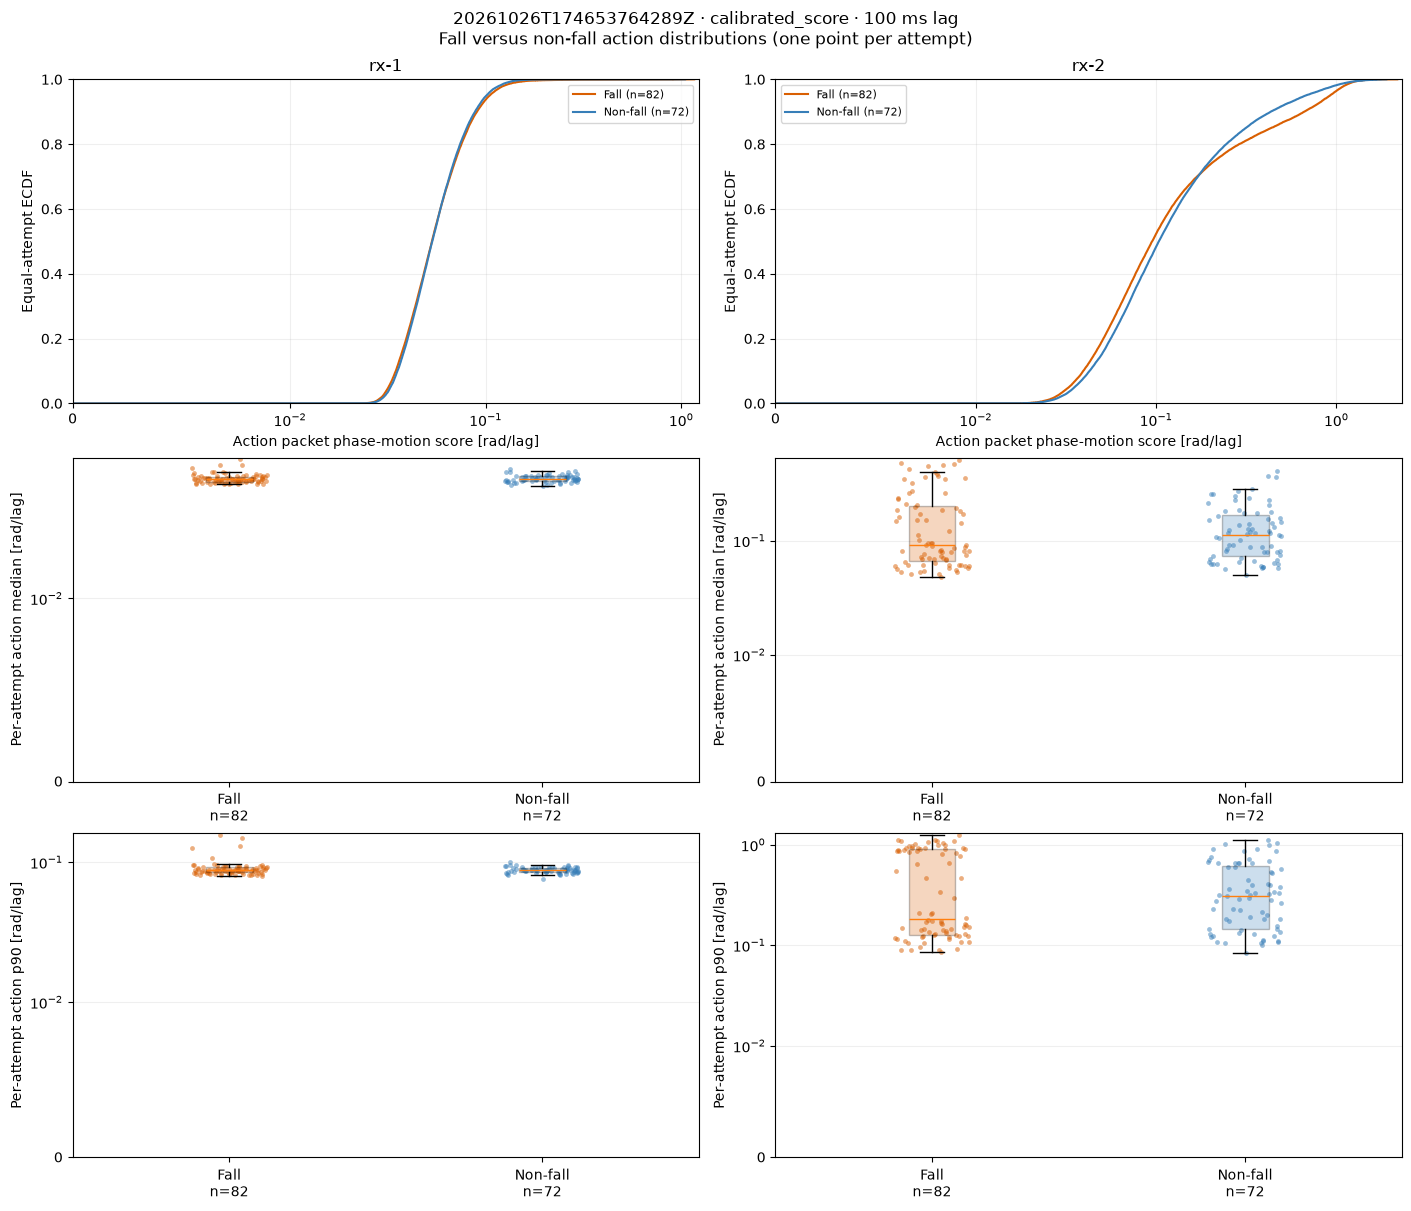

In [27]:
ACTION_COLORS = {"Fall": "#d95f02", "Non-fall": "#377eb8"}
fig, axes = plt.subplots(3, len(RECEIVERS), figsize=(14, 12), squeeze=False, layout="constrained")
for column, receiver in enumerate(RECEIVERS):
    packets = action_packets.loc[action_packets["receiver_id"].eq(receiver)]
    summaries = action_attempts.loc[action_attempts["receiver_id"].eq(receiver)]
    for kind in ACTION_ORDER:
        subset = packets.loc[packets["action_kind"].eq(kind)]
        if not subset.empty:
            x, y = equal_attempt_ecdf(subset)
            axes[0, column].step(x, y, where="post", color=ACTION_COLORS[kind],
                                 label=f"{kind} (n={subset['attempt_id'].nunique()})")
    axes[0, column].set(title=receiver, xlabel="Action packet phase-motion score [rad/lag]", ylabel="Equal-attempt ECDF", ylim=(0, 1))
    axes[0, column].set_xscale("symlog", linthresh=SCORE_LINEAR_RANGE)
    axes[0, column].set_xlim(left=0)
    axes[0, column].legend(fontsize=8)
    axes[0, column].grid(alpha=0.2)
    for row, metric, label in [(1, "median_score", "Per-attempt action median [rad/lag]"),
                               (2, "p90_score", "Per-attempt action p90 [rad/lag]")]:
        attempt_boxplot(axes[row, column], summaries, "action_kind", ACTION_ORDER, metric, ACTION_COLORS)
        axes[row, column].set_ylabel(label)
fig.suptitle(f"{session['session_id']} · {SCORE_COLUMN} · {MOTION_LAG_SECONDS * 1000:g} ms lag\nFall versus non-fall action distributions (one point per attempt)")
action_distribution_path = COMPARISON_FIGURE_DIR / "fall-vs-nonfall-actions.png"
fig.savefig(action_distribution_path, dpi=150)
plt.show()
plt.close(fig)

#### Check action against stationary phases within the same attempt

Subtract each attempt's countdown/recovery median from its action median, separately by receiver and action kind. Positive values mean higher typical motion during action. These paired differences complement the class distributions; a difference in group medians can coexist with substantial overlap.

In [28]:
paired_scores = attempt_phase_scores.pivot(
    index=["attempt_id", "receiver_id", "activity_label", "action_kind"], columns="phase", values="median_score",
).reset_index()
paired_scores["action_minus_countdown"] = paired_scores["action"] - paired_scores["countdown"]
paired_scores["action_minus_recovery"] = paired_scores["action"] - paired_scores["recovery"]
display(paired_scores.groupby(["receiver_id", "action_kind"]).agg(
    attempts=("attempt_id", "nunique"),
    median_action_minus_countdown=("action_minus_countdown", "median"),
    fraction_action_above_countdown=("action_minus_countdown", lambda values: values.gt(0).mean()),
    median_action_minus_recovery=("action_minus_recovery", "median"),
    fraction_action_above_recovery=("action_minus_recovery", lambda values: values.gt(0).mean()),
))

summary_dir = ROOT / "data/interim/phase-motion" / session["session_id"]
summary_dir.mkdir(parents=True, exist_ok=True)
attempt_phase_scores.to_csv(summary_dir / "attempt-phase-scores.csv", index=False)
phase_coverage.to_csv(summary_dir / "phase-score-coverage.csv", index=False)
paired_scores.to_csv(summary_dir / "paired-phase-contrasts.csv", index=False)
print("Saved figures:", phase_distribution_path.relative_to(ROOT), action_distribution_path.relative_to(ROOT), sep="\n")

attempts  median_action_minus_countdown  \
receiver_id action_kind                                            
rx-1        Fall               82                       0.001851   
            Non-fall           72                       0.001985   
rx-2        Fall               82                       0.017377   
            Non-fall           72                       0.019884   

                         fraction_action_above_countdown  \
receiver_id action_kind                                    
rx-1        Fall                                0.743902   
            Non-fall                            0.666667   
rx-2        Fall                                0.792683   
            Non-fall                            0.805556   

                         median_action_minus_recovery  \
receiver_id action_kind                                 
rx-1        Fall                             0.002808   
            Non-fall                         0.001720   
rx-2        Fall                             0.030715   
            Non-fall                         0.044761   

                         fraction_action_above_recovery  
receiver_id action_kind                                  
rx-1        Fall                               0.804878  
            Non-fall                           0.736111  
rx-2        Fall                               0.987805  
            Non-fall                           0.958333

Saved figures:
docs/figures/activity-phases/20261026T174653764289Z/phase-distributions.png
docs/figures/activity-phases/20261026T174653764289Z/fall-vs-nonfall-actions.png


**Reading the pilot:** check whether fall-action curves shift relative to countdown/recovery, whether that shift also occurs for non-fall actions, and how much the fall/non-fall attempt distributions overlap. A clean shift from stationary phases alone demonstrates sensitivity to activity, not fall specificity. Inspect disagreements between receivers and the per-activity counts before interpreting pooled classes. This one-session comparison cannot establish generalization to new participants or sessions.